# Análise Exploratória dos Dados - Classificação de Ativos Financeiros

Este notebook apresenta uma análise exploratória do conjunto de dados de classificação de ativos financeiros. Vamos explorar as características dos dados, distribuições, relações entre variáveis e identificar padrões importantes.

## 1. Importação das Bibliotecas Necessárias

In [22]:
# Bibliotecas para manipulação de dados
import pandas as pd
import numpy as np

# Bibliotecas para visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo para gráficos
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')

# Configura o ambiente para mostrar todos os resultados em DataFrames
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

## 2. Carregamento e Visualização Inicial dos Dados

In [23]:
# Caminho do arquivo de dados processados
filepath = '../data/processed/dataframe_classificado.csv'

# Carrega o arquivo CSV
df = pd.read_csv(filepath)

# Exibe as primeiras linhas do DataFrame para verificar os dados
print(f"Dimensões do DataFrame: {df.shape}")
df.head()

Dimensões do DataFrame: (286146, 8)


,CONTA,FINANCEIRO,QUANTIDADE,NOME ATIVO,TIPO DE ATIVO,PERFIL DA CARTEIRA,CLASSIFICACAO DO ATIVO,Subgrupo
0,27,16278.264089,16.0,CRI CDIE,TITULOS RF PRIVADOS BRASIL,Moderado,Renda Fixa,RF - Títulos Privados Nacionais
1,27,25081.618073,25.0,CRA CDIE,TITULOS RF PRIVADOS BRASIL,Moderado,Renda Fixa,RF - Títulos Privados Nacionais
2,27,47046.248881,49.0,CRA IPCA,TITULOS RF PRIVADOS BRASIL,Moderado,Renda Fixa,RF - Títulos Privados Nacionais
3,27,36331.476685,35.0,RRRP13 IPCA,DEBENTURES BRASIL,Moderado,Renda Fixa,RF - Títulos Privados Nacionais
4,27,18995.623640,20.0,EEELA1 IPCA,DEBENTURES BRASIL,Moderado,Renda Fixa,RF - Títulos Privados Nacionais


In [24]:
# Informações sobre o DataFrame
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286146 entries, 0 to 286145
Data columns (total 8 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   CONTA                   286146 non-null  int64  
 1   FINANCEIRO              286146 non-null  float64
 2   QUANTIDADE              286146 non-null  float64
 3   NOME ATIVO              286146 non-null  object 
 4   TIPO DE ATIVO           286146 non-null  object 
 5   PERFIL DA CARTEIRA      286146 non-null  object 
 6   CLASSIFICACAO DO ATIVO  286146 non-null  object 
 7   Subgrupo                286146 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 17.5+ MB


In [25]:
# Estatísticas descritivas para variáveis numéricas
df.describe()

,CONTA,FINANCEIRO,QUANTIDADE
count,2.861460e+05,2.861460e+05,2.861460e+05
mean,1.773690e+06,1.745078e+06,1.776174e+05
std,1.964002e+06,2.914916e+07,3.421355e+07
min,2.700000e+01,-2.678495e+09,-8.144497e+09
25%,2.343290e+05,6.859315e+03,6.000000e+00
50%,9.149280e+05,3.447960e+04,3.200000e+01
75%,2.651298e+06,3.066296e+05,4.000000e+02
max,6.209173e+06,8.456713e+09,1.425277e+10


## 3. Análise de Valores Ausentes e Duplicados

In [26]:
# Verificação de valores ausentes
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100
missing_data = pd.DataFrame({
    'Valores Ausentes': missing_values,
    'Porcentagem (%)': missing_percentage
})

# Exibe apenas colunas com valores ausentes
missing_data_cols = missing_data[missing_data['Valores Ausentes'] > 0]
if not missing_data_cols.empty:
    print("Colunas com valores ausentes:")
    display(missing_data_cols)
else:
    print("Não há valores ausentes no conjunto de dados.")

Não há valores ausentes no conjunto de dados.


In [27]:
# Verificação de valores duplicados
duplicates = df.duplicated().sum()
print(f"Número de registros duplicados: {duplicates} ({(duplicates/len(df))*100:.2f}%)")

Número de registros duplicados: 10234 (3.58%)


In [28]:
# Remover duplicatas do DataFrame
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)
rows_removed = rows_before - rows_after

print(f"Registros antes da remoção de duplicatas: {rows_before}")
print(f"Registros após a remoção de duplicatas: {rows_after}")
print(f"Total de registros duplicados removidos: {rows_removed} ({(rows_removed/rows_before)*100:.2f}%)")

Registros antes da remoção de duplicatas: 286146
Registros após a remoção de duplicatas: 275912
Total de registros duplicados removidos: 10234 (3.58%)


In [29]:
# ! Só baixando o arquivo sem duplicatas
df.to_csv('../data/processed/dataframe_cleaned.csv', index=False)

## 4. Análise das Variáveis Numéricas

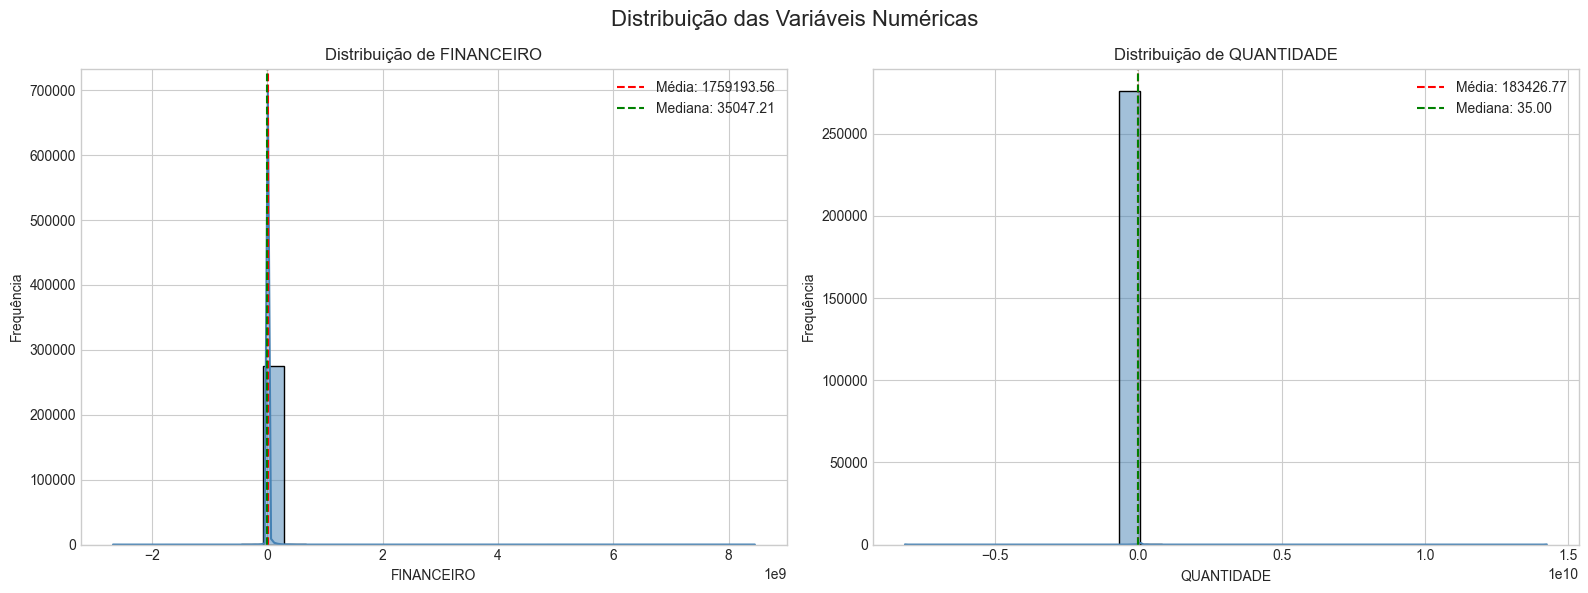

c:\Users\Inteli\.pyenv\pyenv-win\versions\3.12.0\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


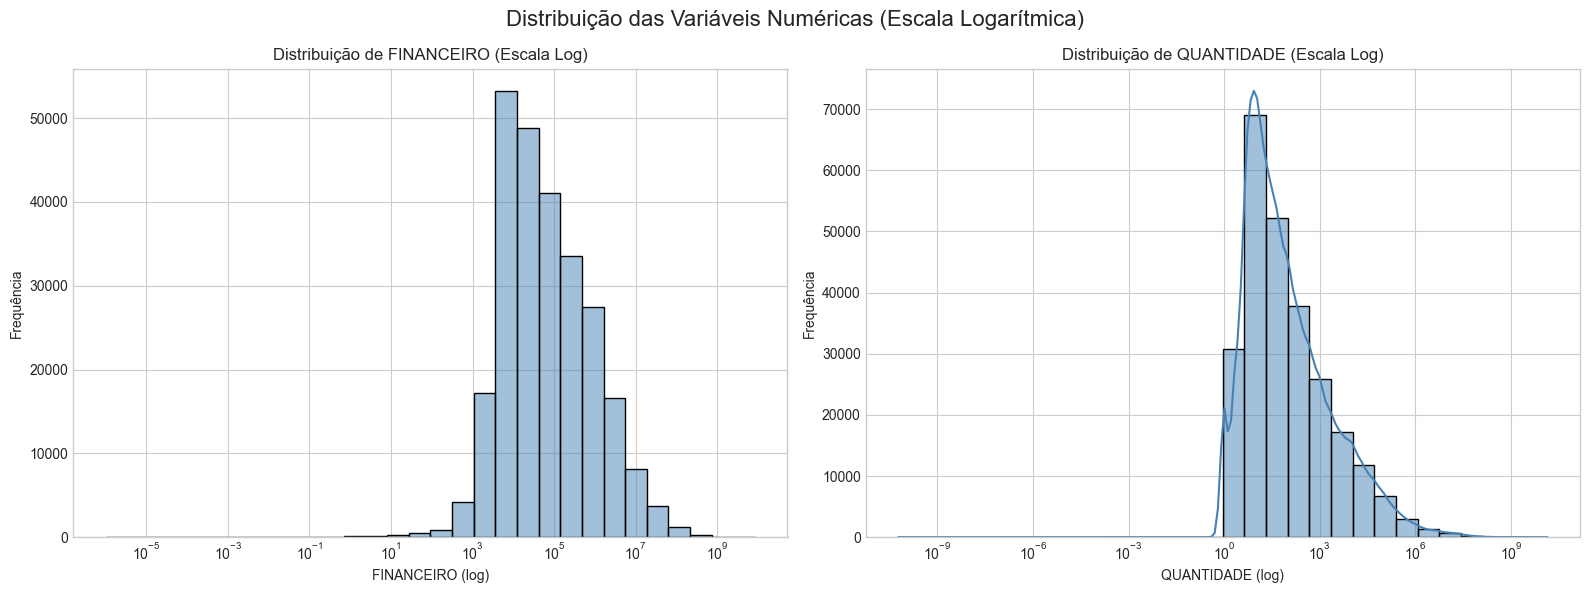

In [30]:
# Selecionando variáveis numéricas para análise
numeric_cols = ['FINANCEIRO', 'QUANTIDADE']

# Criando figura com subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histograma para FINANCEIRO
sns.histplot(df['FINANCEIRO'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].axvline(df['FINANCEIRO'].mean(), color='red', linestyle='--', label=f'Média: {df["FINANCEIRO"].mean():.2f}')
axes[0].axvline(df['FINANCEIRO'].median(), color='green', linestyle='--', label=f'Mediana: {df["FINANCEIRO"].median():.2f}')
axes[0].set_title('Distribuição de FINANCEIRO')
axes[0].set_xlabel('FINANCEIRO')
axes[0].set_ylabel('Frequência')
axes[0].legend()

# Histograma para QUANTIDADE
sns.histplot(df['QUANTIDADE'], bins=30, kde=True, ax=axes[1], color='steelblue')
axes[1].axvline(df['QUANTIDADE'].mean(), color='red', linestyle='--', label=f'Média: {df["QUANTIDADE"].mean():.2f}')
axes[1].axvline(df['QUANTIDADE'].median(), color='green', linestyle='--', label=f'Mediana: {df["QUANTIDADE"].median():.2f}')
axes[1].set_title('Distribuição de QUANTIDADE')
axes[1].set_xlabel('QUANTIDADE')
axes[1].set_ylabel('Frequência')
axes[1].legend()

plt.suptitle('Distribuição das Variáveis Numéricas', fontsize=16)
plt.tight_layout()
plt.show()
# Criando também visualizações com escalas logarítmicas devido à provável assimetria dos dados
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histograma para FINANCEIRO (escala logarítmica)
sns.histplot(df['FINANCEIRO'], bins=30, kde=True, ax=axes[0], color='steelblue', log_scale=True)
axes[0].set_title('Distribuição de FINANCEIRO (Escala Log)')
axes[0].set_xlabel('FINANCEIRO (log)')
axes[0].set_ylabel('Frequência')

# Histograma para QUANTIDADE (escala logarítmica)
sns.histplot(df['QUANTIDADE'], bins=30, kde=True, ax=axes[1], color='steelblue', log_scale=True)
axes[1].set_title('Distribuição de QUANTIDADE (Escala Log)')
axes[1].set_xlabel('QUANTIDADE (log)')
axes[1].set_ylabel('Frequência')

plt.suptitle('Distribuição das Variáveis Numéricas (Escala Logarítmica)', fontsize=16)
plt.tight_layout()
plt.show()


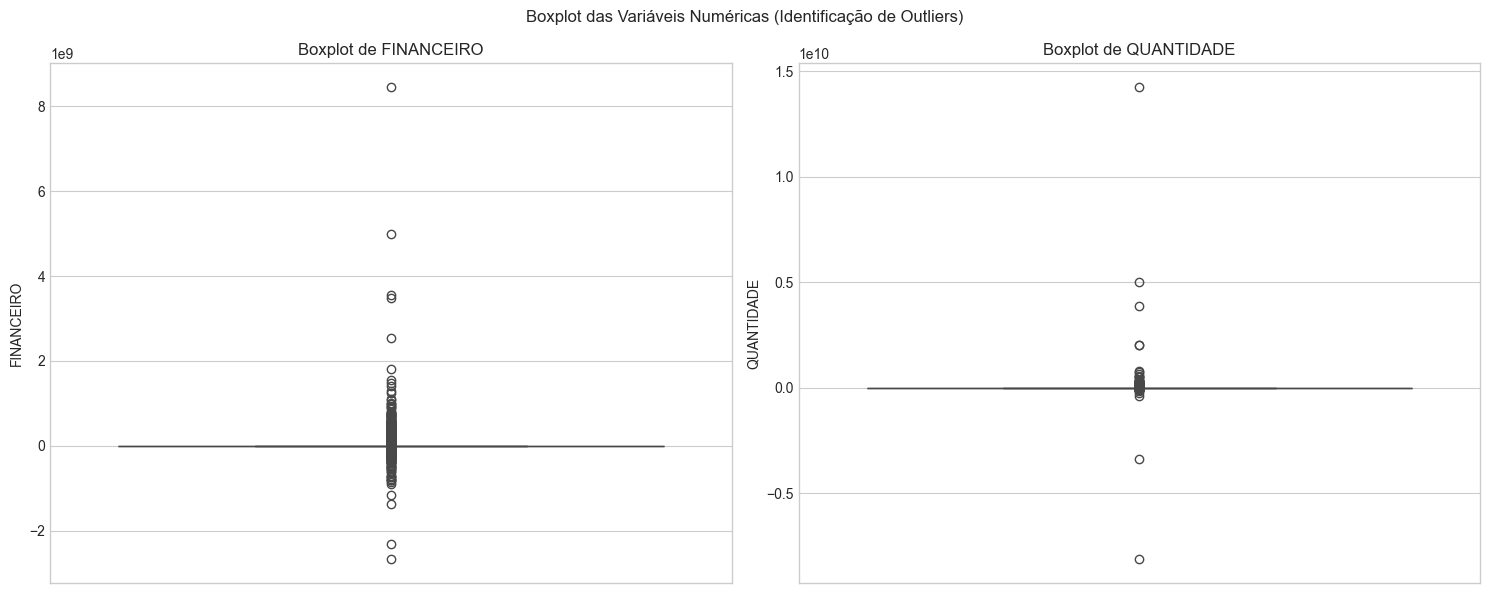

In [31]:
# Boxplot para analisar outliers nas variáveis numéricas usando matplotlib ao invés de plotly
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Criar boxplot para cada coluna numérica
for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='mediumseagreen')
    axes[i].set_title(f'Boxplot de {col}')
    axes[i].set_ylabel(col)
    
plt.suptitle("Boxplot das Variáveis Numéricas (Identificação de Outliers)")
plt.tight_layout()
plt.show()

## 5. Análise das Variáveis Categóricas


Distribuição da variável: TIPO DE ATIVO


,TIPO DE ATIVO,Contagem,Porcentagem (%)
0,DEBENTURES BRASIL,134036,48.58
1,TITULOS RF PRIVADOS BRASIL,63216,22.91
2,ACOES BRASIL,38593,13.99
3,TITULOS RF PUBLICOS BRASIL,26943,9.77
4,OPCOES S/ ACOES BRASIL,4305,1.56
5,CDI DE UM DIA - FUTURO,1711,0.62
6,AÇÕES INTERNACIONAIS,1399,0.51
7,OPÇÃO S/ DISPONÍVEL DE IDI,1167,0.42
8,OPÇÃO FLEXÍVEL AÇÃO BR,1054,0.38
9,CUPOM DE IPCA FUTURO,993,0.36


C:\Users\Inteli\AppData\Local\Temp\ipykernel_88040\4064057293.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=col, y='Contagem', data=value_counts, palette='viridis')


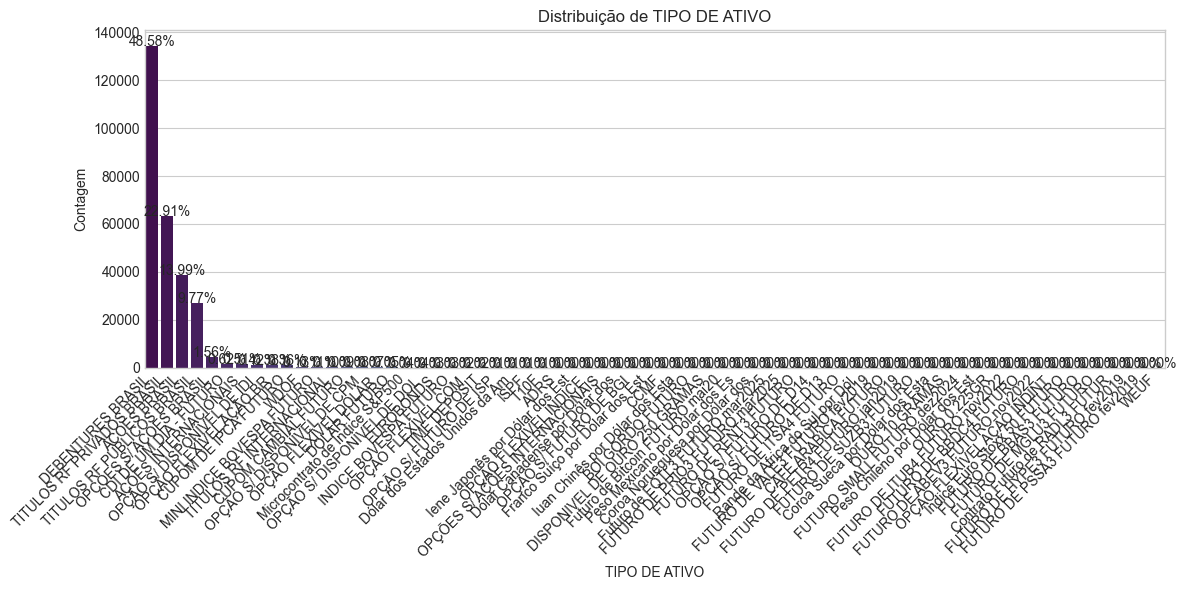


Distribuição da variável: PERFIL DA CARTEIRA


,PERFIL DA CARTEIRA,Contagem,Porcentagem (%)
0,Sofisticado,99066,35.9
1,Conservador,91315,33.1
2,Moderado,85531,31.0


C:\Users\Inteli\AppData\Local\Temp\ipykernel_88040\4064057293.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=col, y='Contagem', data=value_counts, palette='viridis')


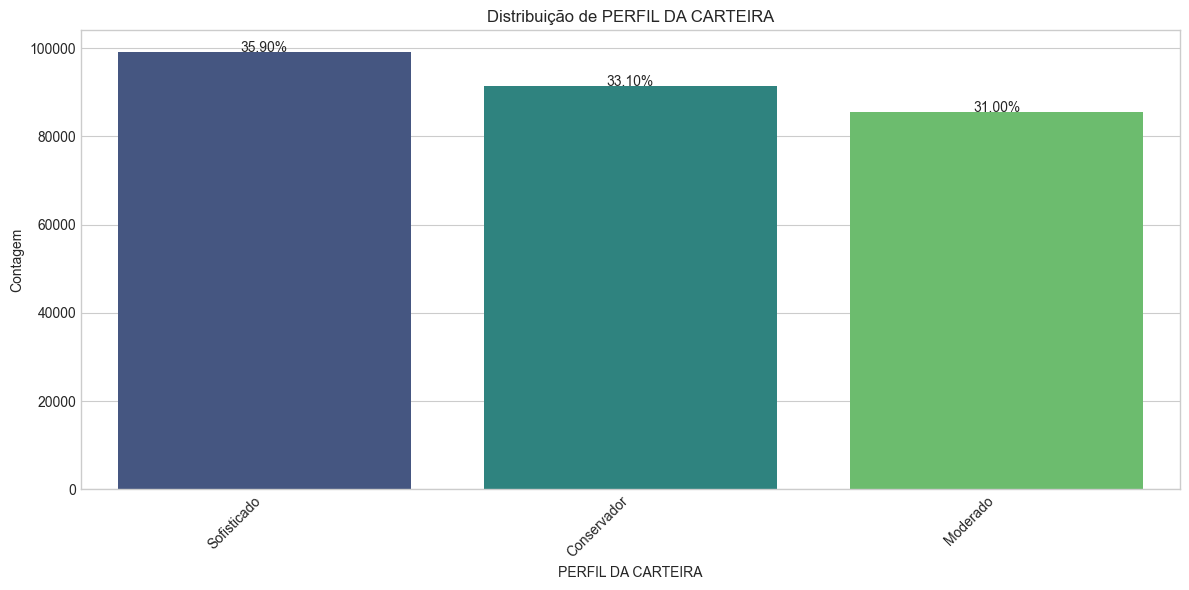


Distribuição da variável: CLASSIFICACAO DO ATIVO


,CLASSIFICACAO DO ATIVO,Contagem,Porcentagem (%)
0,Renda Fixa,227544,82.47
1,Renda Variável,48368,17.53


C:\Users\Inteli\AppData\Local\Temp\ipykernel_88040\4064057293.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=col, y='Contagem', data=value_counts, palette='viridis')


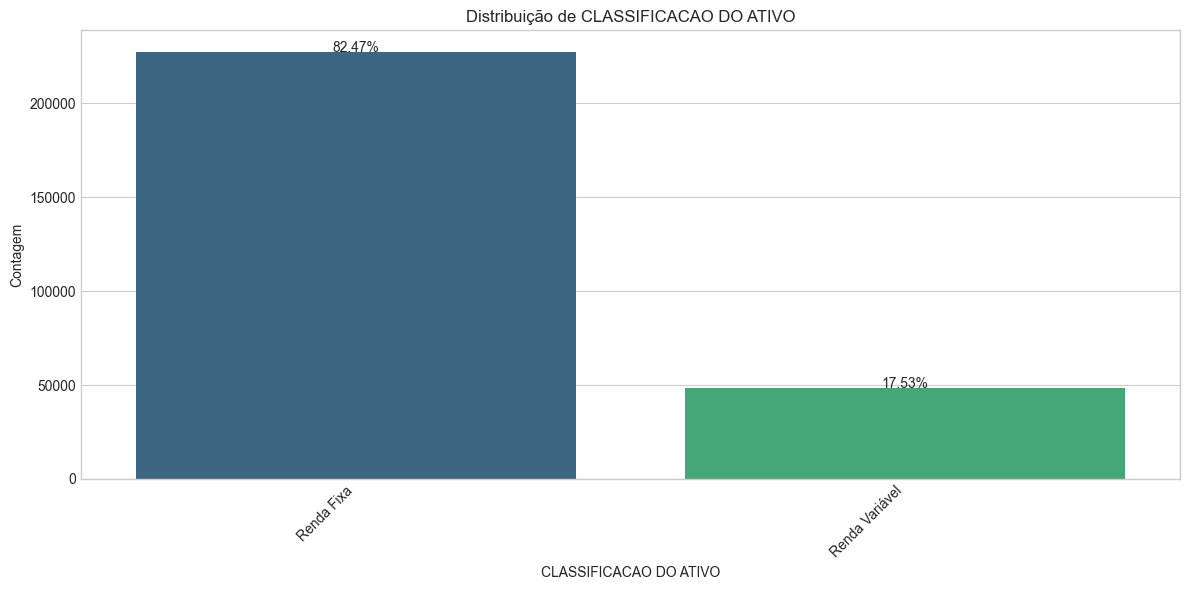

In [32]:
# Analisando a distribuição de cada variável categórica
categorical_cols = ['TIPO DE ATIVO', 'PERFIL DA CARTEIRA', 'CLASSIFICACAO DO ATIVO']

for col in categorical_cols:
    value_counts = df[col].value_counts().reset_index()
    value_counts.columns = [col, 'Contagem']
    percentage = (value_counts['Contagem'] / len(df) * 100).round(2)
    value_counts['Porcentagem (%)'] = percentage
    
    print(f"\nDistribuição da variável: {col}")
    display(value_counts)
    
    # Gráfico de barras usando matplotlib ao invés de plotly
    plt.figure(figsize=(12, 6))
    ax = sns.barplot(x=col, y='Contagem', data=value_counts, palette='viridis')
    
    # Adicionar texto com as porcentagens
    for i, p in enumerate(ax.patches):
        height = p.get_height()
        ax.text(p.get_x() + p.get_width()/2., height + 0.1,
                f'{value_counts["Porcentagem (%)"].iloc[i]:.2f}%',
                ha="center")
    
    plt.title(f'Distribuição de {col}')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

Tabulação cruzada (%) entre PERFIL DA CARTEIRA e CLASSIFICACAO DO ATIVO:


CLASSIFICACAO DO ATIVO,Renda Fixa,Renda Variável
PERFIL DA CARTEIRA,,
Conservador,82.559273,17.440727
Moderado,84.295752,15.704248
Sofisticado,80.810773,19.189227


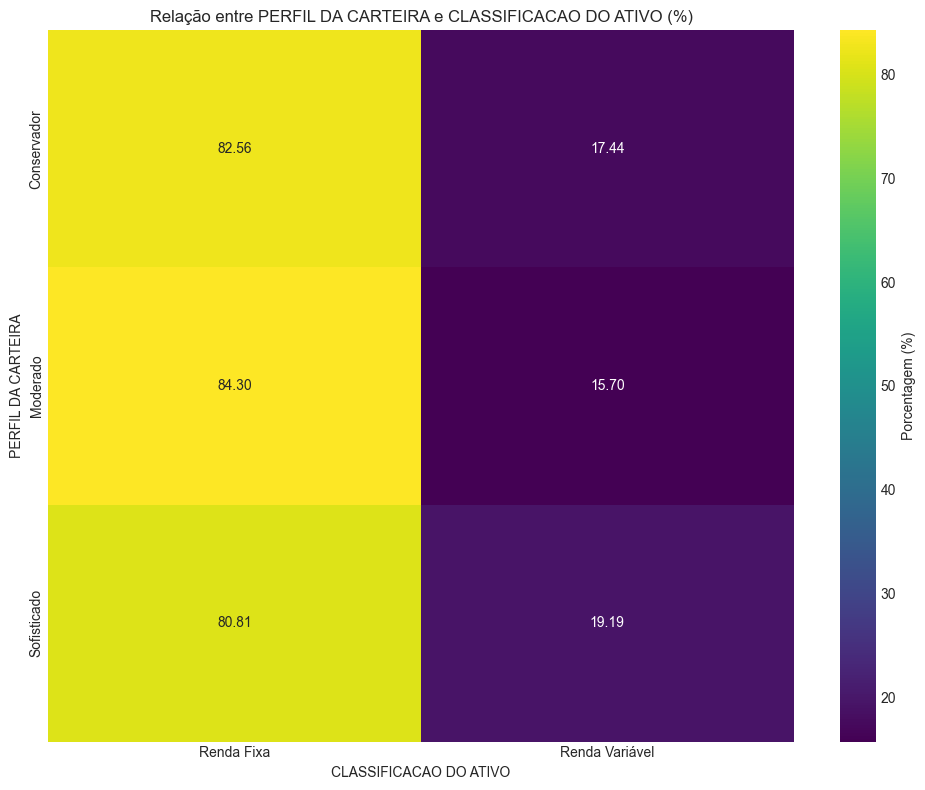

In [33]:
# Análise de tabulação cruzada entre PERFIL DA CARTEIRA e CLASSIFICACAO DO ATIVO
cross_tab = pd.crosstab(df['PERFIL DA CARTEIRA'], 
                        df['CLASSIFICACAO DO ATIVO'], 
                        normalize='index') * 100

print("Tabulação cruzada (%) entre PERFIL DA CARTEIRA e CLASSIFICACAO DO ATIVO:")
display(cross_tab)

# Heatmap para visualizar a relação usando matplotlib/seaborn ao invés de plotly
plt.figure(figsize=(10, 8))
sns.heatmap(cross_tab, annot=True, fmt='.2f', cmap='viridis', cbar_kws={'label': 'Porcentagem (%)'}) 
plt.title('Relação entre PERFIL DA CARTEIRA e CLASSIFICACAO DO ATIVO (%)')
plt.tight_layout()
plt.show()

C:\Users\Inteli\AppData\Local\Temp\ipykernel_88040\2698690398.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='TIPO DE ATIVO', y='Contagem', data=tipo_ativo_counts, palette='viridis')


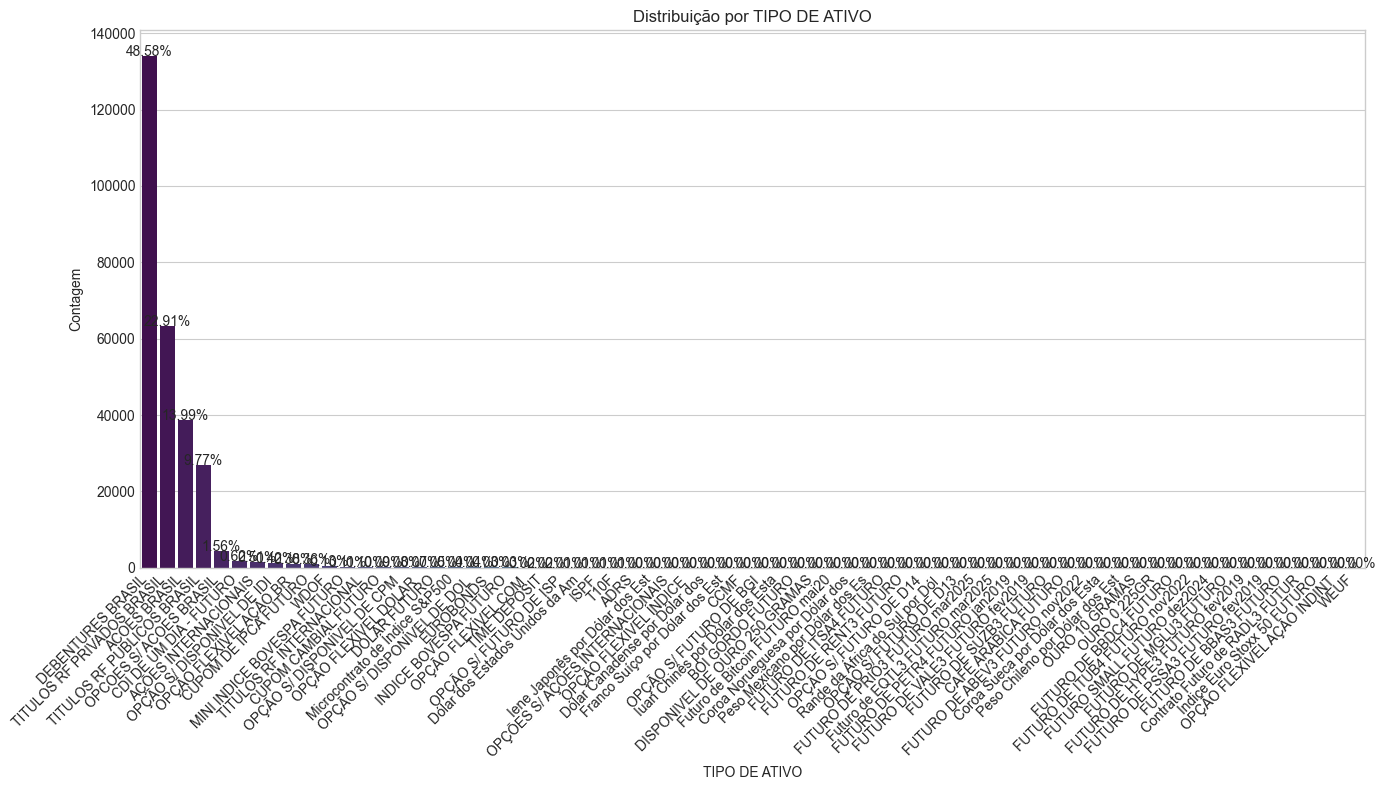

In [34]:
# Análise de acordo com o TIPO DE ATIVO
tipo_ativo_counts = df.groupby(['TIPO DE ATIVO']).size().reset_index(name='Contagem')
tipo_ativo_counts = tipo_ativo_counts.sort_values(by='Contagem', ascending=False)
tipo_ativo_counts['Porcentagem (%)'] = (tipo_ativo_counts['Contagem'] / len(df) * 100).round(2)

# Gráfico de barras para TIPO DE ATIVO usando matplotlib ao invés de plotly
plt.figure(figsize=(14, 8))
ax = sns.barplot(x='TIPO DE ATIVO', y='Contagem', data=tipo_ativo_counts, palette='viridis')

# Adicionar texto com as porcentagens
for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 0.1,
            f'{tipo_ativo_counts["Porcentagem (%)"].iloc[i]:.2f}%',
            ha="center")

plt.title('Distribuição por TIPO DE ATIVO')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

C:\Users\Inteli\AppData\Local\Temp\ipykernel_88040\2932672907.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='NOME ATIVO', y='Contagem', data=top_ativos, palette='viridis')


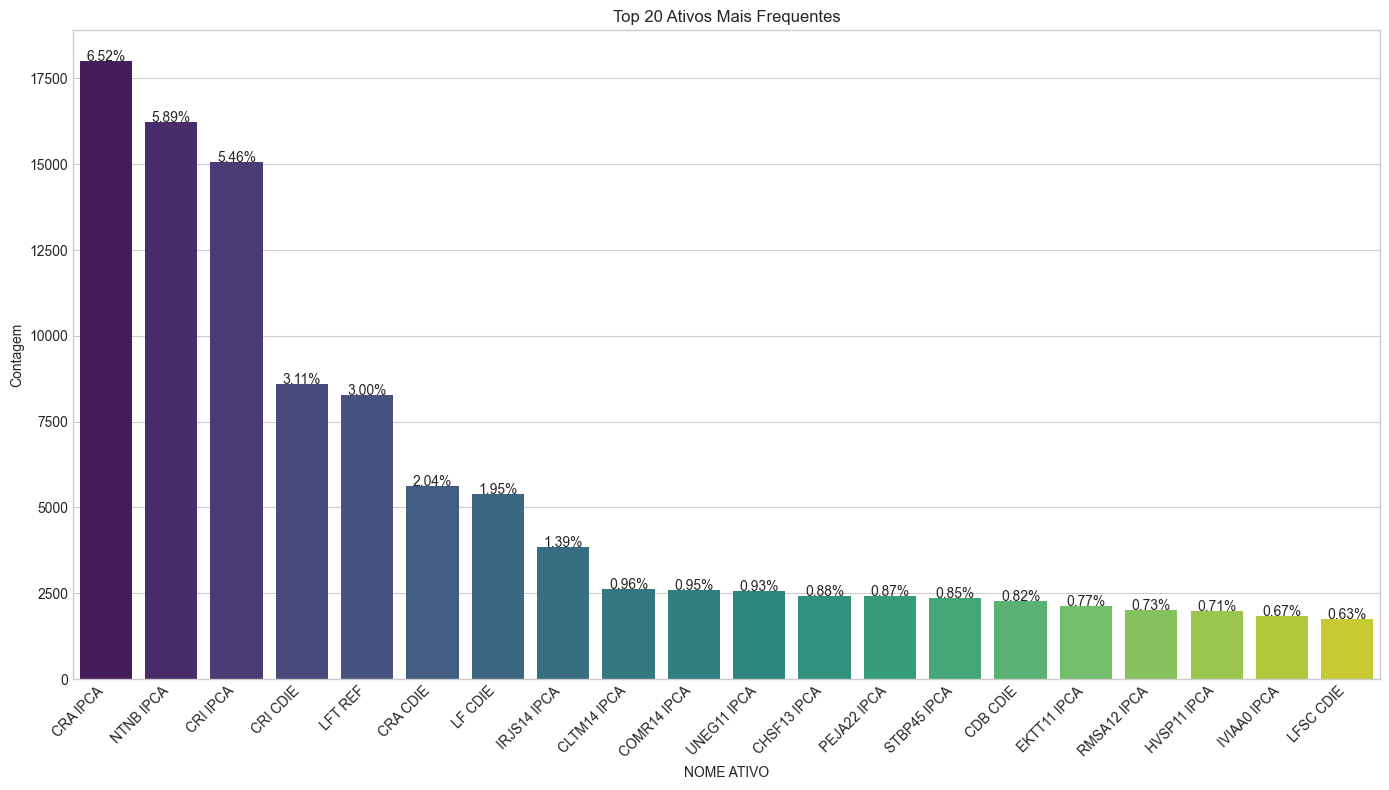

In [35]:
# Análise dos ativos mais frequentes
top_ativos = df['NOME ATIVO'].value_counts().head(20).reset_index()
top_ativos.columns = ['NOME ATIVO', 'Contagem']
top_ativos['Porcentagem (%)'] = (top_ativos['Contagem'] / len(df) * 100).round(2)

# Gráfico de barras para os ativos mais frequentes usando matplotlib ao invés de plotly
plt.figure(figsize=(14, 8))
ax = sns.barplot(x='NOME ATIVO', y='Contagem', data=top_ativos, palette='viridis')

# Adicionar texto com as porcentagens
for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2., height + 0.1,
            f'{top_ativos["Porcentagem (%)"].iloc[i]:.2f}%',
            ha="center")

plt.title('Top 20 Ativos Mais Frequentes')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 6. Análise de Relações Entre Categorias e Valores Financeiros

In [36]:
# Análise do valor financeiro por tipo de ativo e perfil da carteira
financeiro_agrupado = df.groupby(['TIPO DE ATIVO', 'PERFIL DA CARTEIRA'])['FINANCEIRO'].agg(['sum', 'mean', 'count']).reset_index()
financeiro_agrupado.columns = ['TIPO DE ATIVO', 'PERFIL DA CARTEIRA', 'Soma FINANCEIRO', 'Média FINANCEIRO', 'Contagem']
financeiro_agrupado = financeiro_agrupado.sort_values(by='Soma FINANCEIRO', ascending=False)

# Exibe os resultados
financeiro_agrupado

,TIPO DE ATIVO,PERFIL DA CARTEIRA,Soma FINANCEIRO,Média FINANCEIRO,Contagem
156,TITULOS RF PUBLICOS BRASIL,Conservador,8.316233e+10,8.141197e+06,10215
157,TITULOS RF PUBLICOS BRASIL,Moderado,5.961988e+10,7.718783e+06,7724
158,TITULOS RF PUBLICOS BRASIL,Sofisticado,5.443867e+10,6.046053e+06,9004
0,ACOES BRASIL,Conservador,4.529244e+10,3.743796e+06,12098
154,TITULOS RF PRIVADOS BRASIL,Moderado,4.099421e+10,1.906974e+06,21497
...,...,...,...,...,...
111,OPÇÃO FLEXÍVEL DOLAR,Conservador,-1.736917e+08,-4.039341e+06,43
103,OPCOES S/ ACOES BRASIL,Conservador,-2.372246e+08,-1.963780e+05,1208
113,OPÇÃO FLEXÍVEL DOLAR,Sofisticado,-3.112972e+08,-5.276223e+06,59
112,OPÇÃO FLEXÍVEL DOLAR,Moderado,-4.826029e+08,-5.245683e+06,92


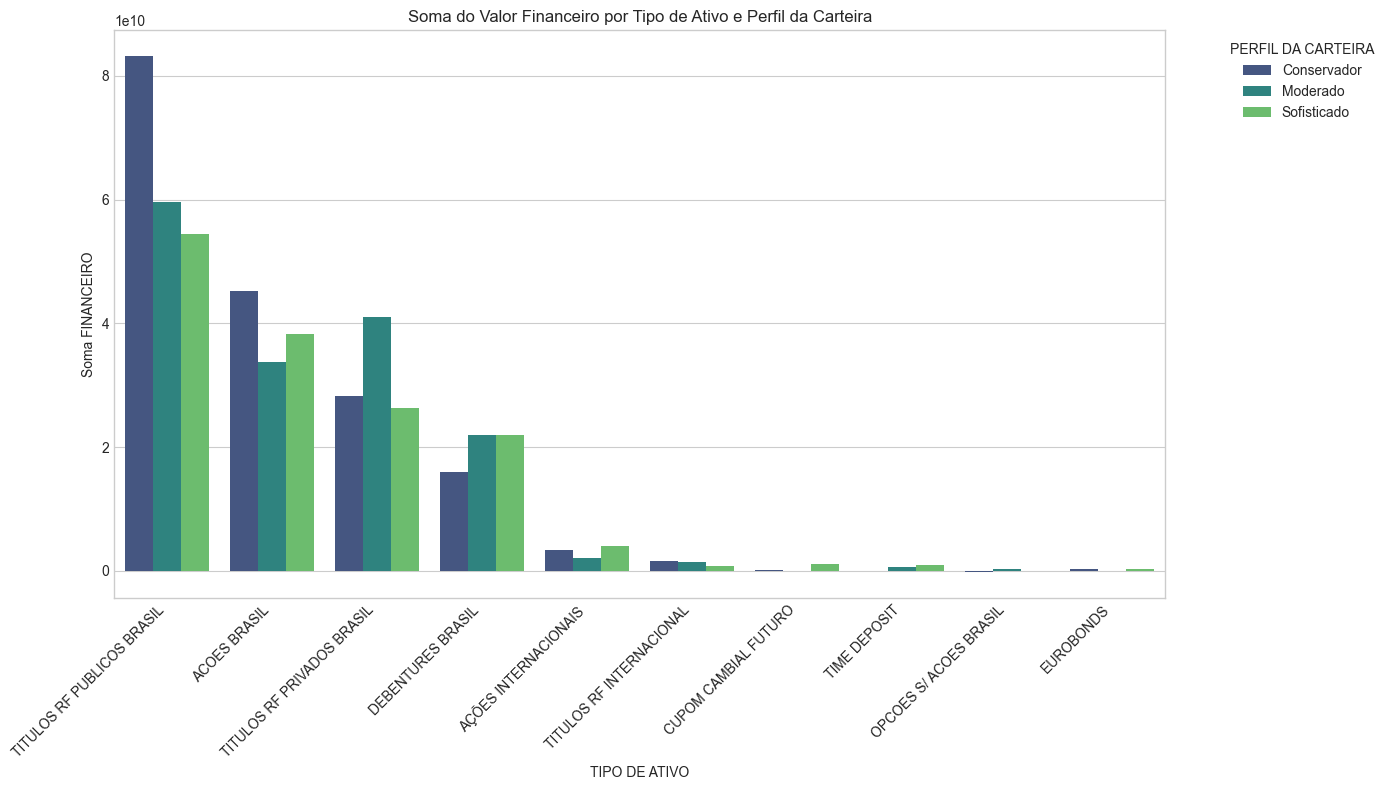

In [37]:
# Gráfico de barras para valor financeiro por tipo de ativo e perfil usando matplotlib ao invés de plotly
# Pegando os top 10 tipos de ativos para melhor visualização
top_tipos = financeiro_agrupado['TIPO DE ATIVO'].unique()[:10]
fin_plot_data = financeiro_agrupado[financeiro_agrupado['TIPO DE ATIVO'].isin(top_tipos)]

plt.figure(figsize=(14, 8))
sns.barplot(x='TIPO DE ATIVO', y='Soma FINANCEIRO', hue='PERFIL DA CARTEIRA', data=fin_plot_data, palette='viridis')
plt.title('Soma do Valor Financeiro por Tipo de Ativo e Perfil da Carteira')
plt.xticks(rotation=45, ha='right')
plt.legend(title='PERFIL DA CARTEIRA', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

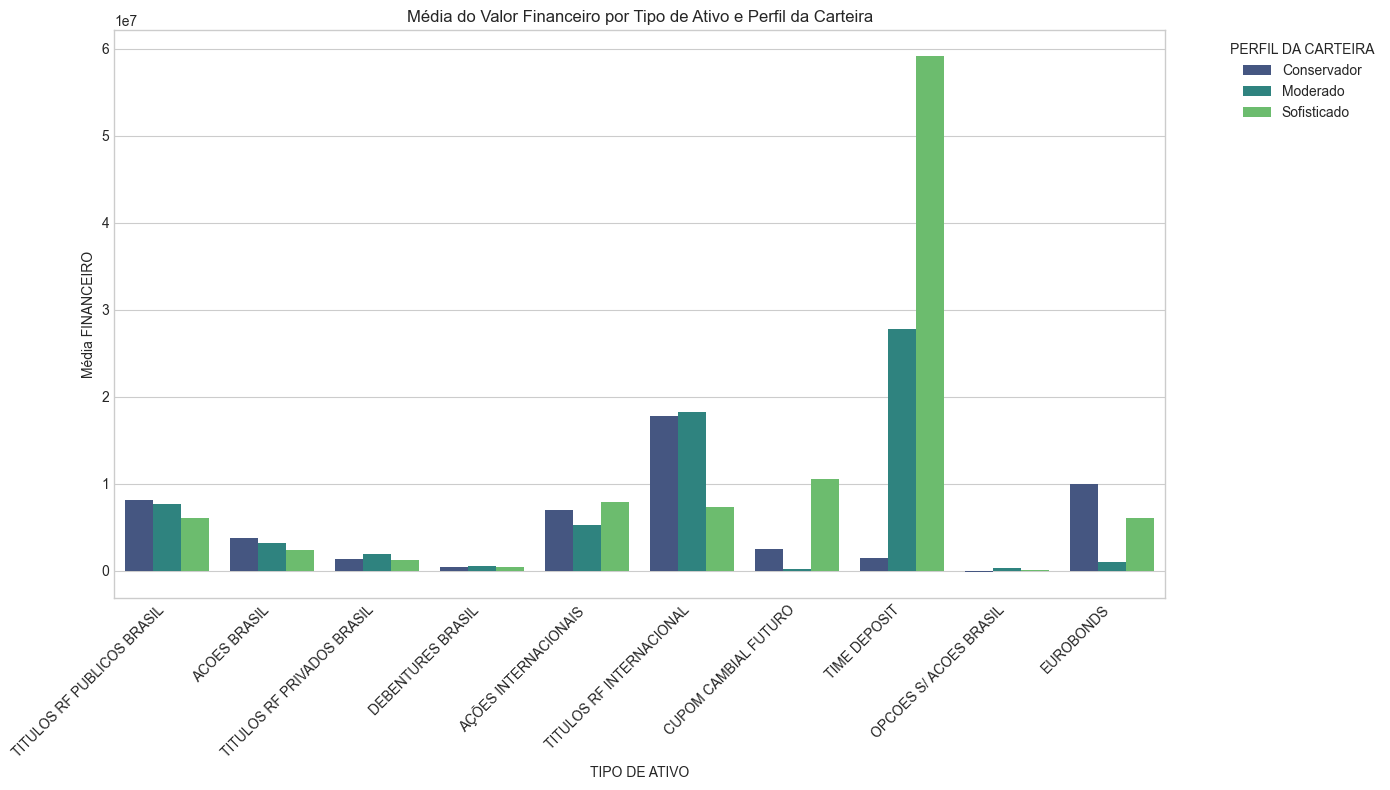

In [38]:
# Gráfico de barras para valor financeiro médio por tipo de ativo e perfil usando matplotlib ao invés de plotly
plt.figure(figsize=(14, 8))
sns.barplot(x='TIPO DE ATIVO', y='Média FINANCEIRO', hue='PERFIL DA CARTEIRA', data=fin_plot_data, palette='viridis')
plt.title('Média do Valor Financeiro por Tipo de Ativo e Perfil da Carteira')
plt.xticks(rotation=45, ha='right')
plt.legend(title='PERFIL DA CARTEIRA', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

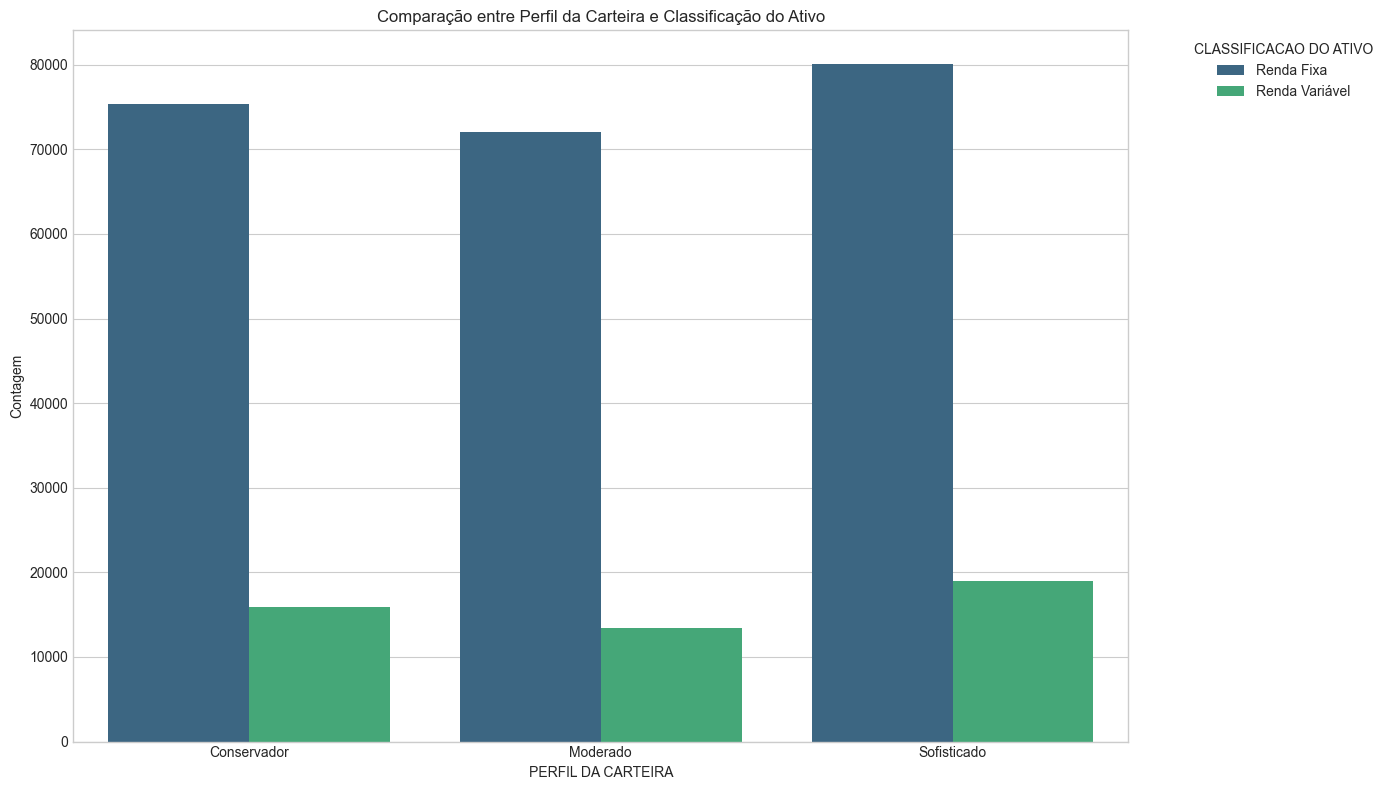

In [39]:
# Análise da classificação do ativo em relação ao perfil da carteira
classificacao_vs_perfil = df.groupby(['PERFIL DA CARTEIRA', 'CLASSIFICACAO DO ATIVO']).size().reset_index(name='Contagem')

# Gráfico de barras comparando classificação vs perfil usando matplotlib ao invés de plotly
plt.figure(figsize=(14, 8))
sns.barplot(x='PERFIL DA CARTEIRA', y='Contagem', hue='CLASSIFICACAO DO ATIVO', data=classificacao_vs_perfil, palette='viridis')
plt.title('Comparação entre Perfil da Carteira e Classificação do Ativo')
plt.legend(title='CLASSIFICACAO DO ATIVO', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 7. Análise por Conta

In [40]:
# Análise da distribuição de contas
conta_counts = df['CONTA'].value_counts().reset_index()
conta_counts.columns = ['CONTA', 'Contagem']
conta_counts = conta_counts.sort_values(by='Contagem', ascending=False)

# Calculando o valor financeiro total por conta
conta_financeiro = df.groupby('CONTA')['FINANCEIRO'].sum().reset_index()
conta_financeiro = conta_financeiro.sort_values(by='FINANCEIRO', ascending=False)

# Exibe as contas com mais registros
print("\nContas com mais registros:")
display(conta_counts.head(10))

# Exibe as contas com maior valor financeiro
print("\nContas com maior valor financeiro:")
display(conta_financeiro.head(10))


Contas com mais registros:


,CONTA,Contagem
0,4577281,1388
1,33580,1366
2,151946,1131
3,391746,1054
4,2480636,1028
5,164300,1016
6,185257,899
7,5999710,851
8,5748504,845
9,1767514,841



Contas com maior valor financeiro:


,CONTA,FINANCEIRO
251,29511,1.976232e+10
837,151946,1.866244e+10
5596,5764323,1.280174e+10
523,95708,9.195777e+09
441,91397,7.423045e+09
2017,424858,6.968683e+09
4030,1785056,6.515575e+09
3275,1141118,5.367303e+09
7,744,5.153674e+09
4199,2480637,5.041400e+09


In [41]:
# Analisa o perfil e classificação por conta
conta_perfil_classificacao = df.groupby('CONTA')[['PERFIL DA CARTEIRA', 'CLASSIFICACAO DO ATIVO']].agg(lambda x: x.value_counts().index[0])
conta_perfil_classificacao = conta_perfil_classificacao.reset_index()

# Junta com informações de contagem e valor financeiro
conta_analysis = pd.merge(conta_counts, conta_financeiro, on='CONTA')
conta_analysis = pd.merge(conta_analysis, conta_perfil_classificacao, on='CONTA')
conta_analysis['Valor Médio por Registro'] = conta_analysis['FINANCEIRO'] / conta_analysis['Contagem']

# Exibe as informações consolidadas
display(conta_analysis.head(10))

,CONTA,Contagem,FINANCEIRO,PERFIL DA CARTEIRA,CLASSIFICACAO DO ATIVO,Valor Médio por Registro
0,4577281,1388,1.687313e+08,Conservador,Renda Fixa,1.215643e+05
1,33580,1366,9.680049e+08,Moderado,Renda Variável,7.086419e+05
2,151946,1131,1.866244e+10,Moderado,Renda Fixa,1.650083e+07
3,391746,1054,3.017339e+08,Sofisticado,Renda Fixa,2.862750e+05
4,2480636,1028,1.347181e+09,Sofisticado,Renda Variável,1.310487e+06
5,164300,1016,1.112518e+09,Sofisticado,Renda Fixa,1.094998e+06
6,185257,899,5.388555e+08,Conservador,Renda Variável,5.993943e+05
7,5999710,851,2.572798e+09,Sofisticado,Renda Fixa,3.023265e+06
8,5748504,845,6.376256e+08,Sofisticado,Renda Fixa,7.545865e+05
9,1767514,841,2.290282e+08,Sofisticado,Renda Fixa,2.723284e+05


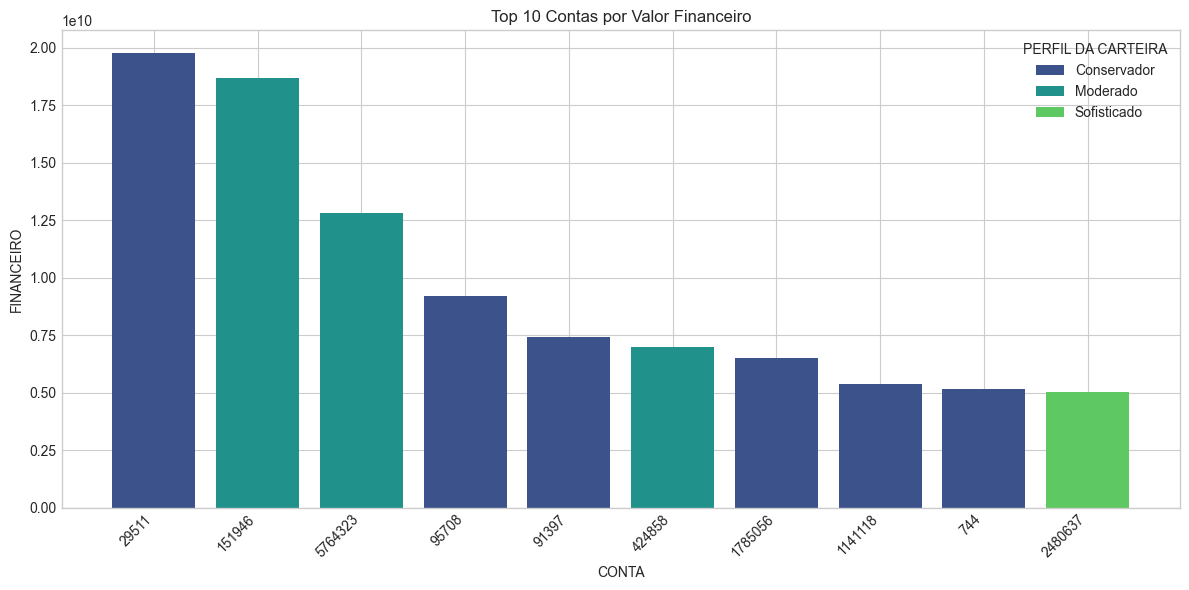

In [42]:
# Gráfico para as 10 contas com maior valor financeiro usando matplotlib ao invés de plotly
top_contas = conta_analysis.sort_values(by='FINANCEIRO', ascending=False).head(10)

plt.figure(figsize=(12, 6))
# Usar cores diferentes para diferentes perfis
perfis = top_contas['PERFIL DA CARTEIRA'].unique()
colors = sns.color_palette('viridis', len(perfis))
color_map = dict(zip(perfis, colors))

bars = plt.bar(top_contas['CONTA'].astype(str), top_contas['FINANCEIRO'], 
       color=[color_map[perfil] for perfil in top_contas['PERFIL DA CARTEIRA']])

plt.title('Top 10 Contas por Valor Financeiro')
plt.xlabel('CONTA')
plt.ylabel('FINANCEIRO')
plt.xticks(rotation=45, ha='right')

# Adicionar legenda para os perfis
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color_map[perfil], label=perfil) for perfil in perfis]
plt.legend(handles=legend_elements, title='PERFIL DA CARTEIRA')

plt.tight_layout()
plt.show()

## 9. Conclusões da Análise Exploratória

Com base na análise exploratória realizada, podemos observar alguns pontos importantes sobre o conjunto de dados de classificação de ativos financeiros:

1. **Distribuição dos dados**:
   - A maior parte dos ativos no conjunto de dados são do tipo "DEBENTURES BRASIL" e "TITULOS RF PRIVADOS BRASIL"
   - Os perfis de carteira predominantes são "Moderado" e "Conservador"
   - A classificação dos ativos é majoritariamente "Moderado"

2. **Relação entre variáveis numéricas**:
   - Existe uma correlação positiva entre o valor financeiro e a quantidade de ativos
   - Há presença de alguns valores extremos (outliers) tanto no valor financeiro quanto nas quantidades

3. **Concordância entre perfil e classificação**:
   - Existe uma alta taxa de concordância entre o perfil da carteira e a classificação do ativo
   - A concordância varia dependendo do tipo de ativo
   - Os perfis têm diferentes taxas de concordância, com alguns perfis apresentando maior discrepância

4. **Comportamento por conta**:
   - Algumas contas concentram um volume significativo de ativos
   - Existem diferenças notáveis no valor financeiro médio entre as contas
   - O perfil predominante varia entre as contas

Estas observações fornecem insights valiosos sobre o comportamento dos dados e podem ser usadas como base para a criação de um modelo de classificação adequado para este contexto financeiro.